# Spam/Ham Classifier

## a) Vocabulary and count matrix

In [12]:
import csv
from collections import Counter
import numpy as np

with open('sms.csv', encoding='utf-8-sig', newline='') as f:
    data = list(csv.DictReader(f))

N = len(data)
perm = np.random.default_rng(0).permutation(N)
n_train = int(.8 * N)
n_fit = int(.75 * n_train)
fit_idx, val_idx, test_idx = perm[:n_fit], perm[n_fit:n_train], perm[n_train:]
tokens = [data[i]['message'].lower().split() for i in fit_idx]
frequency = Counter(word for message in tokens for word in set(message))
vocabulary = sorted(word for word, count in frequency.items() if count >= 5)
word_index = {word: j for j, word in enumerate(vocabulary)}
X_fit = np.zeros((n_fit, len(vocabulary)), dtype=np.int32)

for i, message in enumerate(tokens):
    for word, count in Counter(message).items():
        if word in word_index:
            X_fit[i, word_index[word]] = count

print(f'Vocabulary size: {len(vocabulary)}')

Vocabulary size: 1363


## b) Multinomial Naive Bayes with Laplace smoothing
$N_{jw}$ is the count of word $w$ in class $j$, $N_j=\sum_wN_{jw}$ and $V$ the vocabulary size, Laplace smoothing gives
$$P(w\mid\omega_j)=\frac{N_{jw}+1}{N_j+V}$$
For a message with counts $x_w$, calculate the discriminant function (log score)
$$g_j(x)=\log P(\omega_j)+\sum_w x_w\log P(w\mid\omega_j)$$
Use class 0 for ham and class 1 for spam. Predict spam when $g_1-g_0>0$, and ham otherwise. Test messages use the fitting vocabulary.

In [13]:
y_fit = np.array([data[i]['label'] == 'spam' for i in fit_idx], dtype=int)
word_counts = np.array([X_fit[y_fit == j].sum(axis=0) for j in range(2)])
log_priors = np.log(np.bincount(y_fit, minlength=2) / len(y_fit))
log_word_probs = np.log(word_counts + 1) - np.log(word_counts.sum(axis=1, keepdims=True) + len(vocabulary))

X_test = np.zeros((len(test_idx), len(vocabulary)), dtype=np.int32)
for i, index in enumerate(test_idx):
    for word, count in Counter(data[index]['message'].lower().split()).items():
        if word in word_index:
            X_test[i, word_index[word]] = count

scores = X_test @ log_word_probs.T + log_priors
log_odds = scores[:, 1] - scores[:, 0]
y_pred = (log_odds > 0).astype(int)
y_test = np.array([data[i]['label'] == 'spam' for i in test_idx], dtype=int)
print(f'Test accuracy: {(y_pred == y_test).mean():.4%}')

Test accuracy: 97.9372%


## c) Words most strongly associated with spam
Rank the fitting-vocabulary words by
$$r(w)=\log\frac{P(w\mid\text{spam})}{P(w\mid\text{ham})}=\log P(w\mid\text{spam})-\log P(w\mid\text{ham})$$

In [14]:
word_log_ratios = log_word_probs[1] - log_word_probs[0]
top_words = np.argsort(-word_log_ratios, kind='stable')[:5]
for rank, index in enumerate(top_words, 1):
    print(f'{rank}. {vocabulary[index]:<15} {word_log_ratios[index]:.6f}')

1. claim           5.454619
2. won             5.025057
3. prize           4.777221
4. urgent!         4.643689
5. awarded         4.569581


## d) Confusion matrix and spam metrics
The confusion matrix has rows predicted and columns true:
$$C=\begin{pmatrix}TN&FN\\FP&TP\end{pmatrix}$$
For the spam class
$$\text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\,\text{Precision}\,\text{Recall}}{\text{Precision}+\text{Recall}}=\frac{2TP}{2TP+FP+FN}$$

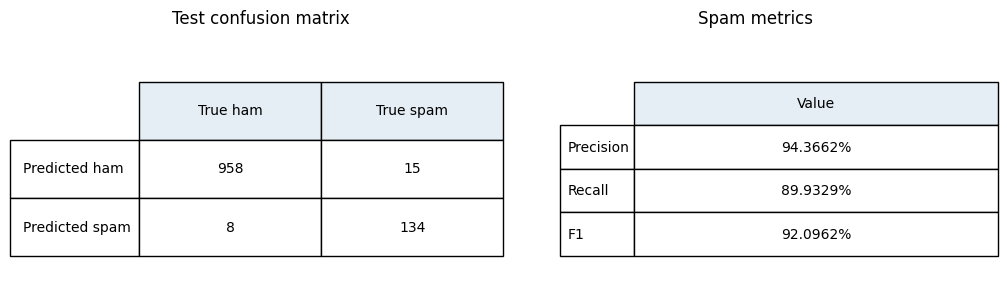

In [15]:
import matplotlib.pyplot as plt

confusion = np.array([[np.sum((y_pred == i) & (y_test == j)) for j in range(2)] for i in range(2)])
TP, FP, FN = confusion[1, 1], confusion[1, 0], confusion[0, 1]
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * TP / (2 * TP + FP + FN)

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), constrained_layout=True)
for ax in axes:
    ax.axis('off')
axes[0].set_title('Test confusion matrix')
axes[0].table(cellText=confusion, rowLabels=['Predicted ham', 'Predicted spam'],
              colLabels=['True ham', 'True spam'], cellLoc='center',
              colColours=['#e6eef5'] * 2, bbox=[.25, .1, .75, .7])
axes[1].set_title('Spam metrics')
axes[1].table(cellText=[[f'{value:.4%}'] for value in [precision, recall, f1]],
              rowLabels=['Precision', 'Recall', 'F1'], colLabels=['Value'],
              cellLoc='center', colColours=['#e6eef5'], bbox=[.25, .1, .75, .7])
plt.show()

## e) ROC curve and AUC
For consecutive ROC points $(u_i,v_i)=(\mathrm{FPR}_i,\mathrm{TPR}_i)$, the trapezoid rule gives
$$\mathrm{AUC}_{\mathrm{trap}}=\sum_i (u_{i+1}-u_i)\frac{v_i+v_{i+1}}{2}$$
Independently, compare every actual spam score with every actual ham score:
$$\mathrm{AUC}_{\mathrm{pairs}}=
\frac{\sum_{a\in\mathrm{spam}}\sum_{b\in\mathrm{ham}}
\left[\mathbf{1}\{s_a>s_b\}+\frac12\mathbf{1}\{s_a=s_b\}\right]}
{N_{\mathrm{spam}}N_{\mathrm{ham}}}$$

AUC (trapezoid): 0.9757909875
AUC (pairs):     0.9757909875


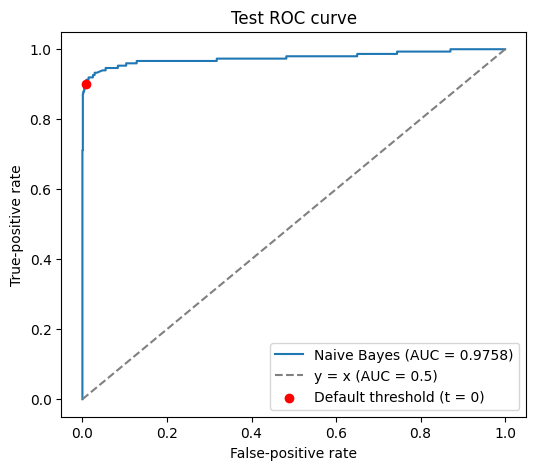

In [16]:
spam_scores = log_odds[y_test == 1]
ham_scores = log_odds[y_test == 0]
thresholds = np.r_[np.inf, np.unique(log_odds)[::-1], -np.inf]
tpr = np.array([(spam_scores > t).mean() for t in thresholds])
fpr = np.array([(ham_scores > t).mean() for t in thresholds])

auc_trapezoid = np.sum(np.diff(fpr) * (tpr[:-1] + tpr[1:]) / 2)
differences = spam_scores[:, None] - ham_scores[None, :]
auc_pairs = (differences > 0).mean() + 0.5 * (differences == 0).mean()
print(f'AUC (trapezoid): {auc_trapezoid:.10f}')
print(f'AUC (pairs):     {auc_pairs:.10f}')

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Naive Bayes (AUC = {auc_trapezoid:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='y = x (AUC = 0.5)')
plt.scatter((ham_scores > 0).mean(), (spam_scores > 0).mean(),
            color='red', zorder=3, label='Default threshold (t = 0)')
plt.xlabel('False-positive rate')
plt.ylabel('True-positive rate')
plt.title('Test ROC curve')
plt.legend(loc='lower right')
plt.show()

## f) Neyman-Pearson threshold

In [17]:
X_val = np.zeros((len(val_idx), len(vocabulary)), dtype=np.int32)
for i, index in enumerate(val_idx):
    for word, count in Counter(data[index]['message'].lower().split()).items():
        if word in word_index:
            X_val[i, word_index[word]] = count

y_val = np.array([data[i]['label'] == 'spam' for i in val_idx], dtype=int)
val_scores = X_val @ log_word_probs.T + log_priors
val_log_odds = val_scores[:, 1] - val_scores[:, 0]
val_thresholds = np.r_[-np.inf, np.unique(val_log_odds), np.inf]
val_fpr = np.array([(val_log_odds[y_val == 0] > t).mean() for t in val_thresholds])
np_threshold = val_thresholds[np.flatnonzero(val_fpr <= 0.01)[0]]

print(f'Neyman-Pearson threshold: {np_threshold:.10f}')
print(f'{"Set / rule":<24} {"FPR":>10} {"Spam / recall":>14}')
for name, odds, labels in [('Validation', val_log_odds, y_val), ('Test', log_odds, y_test)]:
    for rule, t in [('Default', 0), ('Neyman-Pearson', np_threshold)]:
        rate = (odds[labels == 0] > t).mean()
        recall = (odds[labels == 1] > t).mean()
        print(f'{name + " / " + rule:<24} {rate:>10.4%} {recall:>14.4%}')

Neyman-Pearson threshold: -0.2319573928
Set / rule                      FPR  Spam / recall
Validation / Default        0.7209%       87.5000%
Validation / Neyman-Pearson    0.9269%       87.5000%
Test / Default              0.8282%       89.9329%
Test / Neyman-Pearson       1.0352%       91.2752%


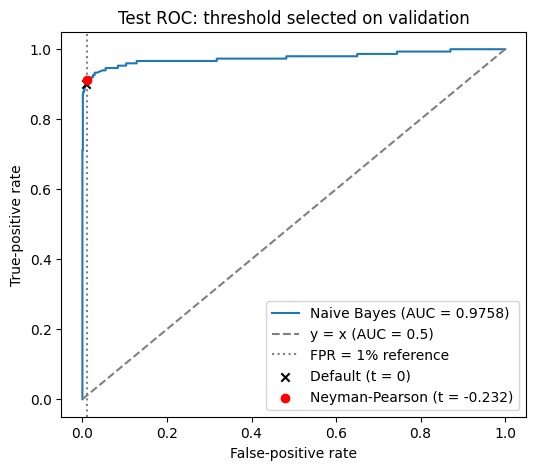

In [18]:
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Naive Bayes (AUC = {auc_trapezoid:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='y = x (AUC = 0.5)')
plt.axvline(0.01, color='gray', linestyle=':', label='FPR = 1% reference')
plt.scatter((ham_scores > 0).mean(), (spam_scores > 0).mean(),
            color='black', marker='x', zorder=3, label='Default (t = 0)')
plt.scatter((ham_scores > np_threshold).mean(), (spam_scores > np_threshold).mean(),
            color='red', zorder=4, label=f'Neyman-Pearson (t = {np_threshold:.3f})')
plt.xlabel('False-positive rate')
plt.ylabel('True-positive rate')
plt.title('Test ROC: threshold selected on validation')
plt.legend(loc='lower right')
plt.show()

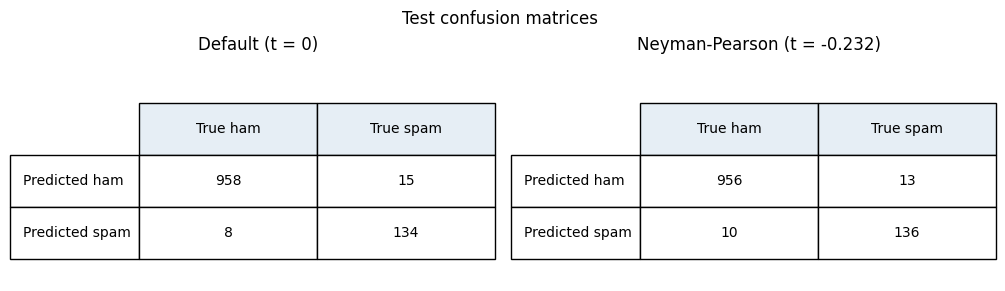

In [20]:
np_pred = (log_odds > np_threshold).astype(int)
np_confusion = np.array([[np.sum((np_pred == i) & (y_test == j))
                          for j in range(2)] for i in range(2)])
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), constrained_layout=True)
for ax, matrix, title in zip(axes, [confusion, np_confusion],
                             ['Default (t = 0)', f'Neyman-Pearson (t = {np_threshold:.3f})']):
    ax.axis('off')
    ax.set_title(title)
    ax.table(cellText=matrix, rowLabels=['Predicted ham', 'Predicted spam'],
             colLabels=['True ham', 'True spam'], cellLoc='center',
             colColours=['#e6eef5'] * 2, bbox=[.25, .1, .75, .7])
fig.suptitle('Test confusion matrices')
plt.show()

On test, recall increases from 89.93% to 91.28%, while FPR increases from 0.8282% to 1.0352%. The 1% validation constraint does not guarantee the same rate on a different test sample.